<a href="https://colab.research.google.com/github/shilnikovAD/agent/blob/main/hw3/homework03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
import os
from pathlib import Path
if not any(Path(p, "fresh_2026.jsonl").exists() for p in ["data", "agent/hw3/data", "agent/hw1/data"]):
    !git clone -q https://github.com/shilnikovAD/agent
try:
    from google.colab import userdata
    os.environ.setdefault("OPENROUTER_API_KEY", userdata.get("OPENROUTER_API_KEY"))
except Exception:
    pass

In [6]:
%pip install -q httpx pydantic python-dotenv pandas matplotlib "langgraph>=1.0" "langchain>=1.0" "langchain-openai>=1.0"

In [7]:

import os, re, json, gzip, time, warnings, difflib
os.environ.setdefault("LANGCHAIN_OPENAI_TCP_KEEPALIVE", "0")
warnings.filterwarnings("ignore")
from pathlib import Path
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
from typing import TypedDict
import httpx
import pandas as pd
import matplotlib.pyplot as plt
from pydantic import BaseModel, Field
from dotenv import load_dotenv
load_dotenv()

KEY = os.getenv("OPENROUTER_API_KEY")
assert KEY, "нет ключа OPENROUTER_API_KEY"

BASE_URL = "https://openrouter.ai/api/v1"
CHEAP, STRONG = os.getenv("CHEAP_MODEL", "openai/gpt-4o-mini"), os.getenv("STRONG_MODEL", "anthropic/claude-sonnet-4.6")
COLORS = {"violet": "#5436A3", "amber": "#F09000", "teal": "#00838F", "red": "#C43C3C", "grey": "#787882"}
DATA = next((p for p in [Path("data"), Path("agent/hw3/data"), Path("agent/hw1/data")] if (p / "fresh_2026.jsonl").exists()), Path("data"))
SAMPLE, STRONG_SAMPLE = 40, 40
Path("img").mkdir(exist_ok=True)
pd.set_option("display.max_colwidth", 200)

def load_jsonl(name):
    return [json.loads(line) for line in (DATA / name).read_text(encoding="utf-8").splitlines() if line.strip()]

def pmap(fn, items, workers=6):
    with ThreadPoolExecutor(workers) as ex:
        return list(ex.map(fn, items))

In [8]:
CALLS, FIRST, TAG = [], {}, {"now": "без метки"}

def on_response(response):
    response.read()
    if response.status_code != 200:
        return
    request = json.loads(response.request.content or b"{}")
    usage = response.json().get("usage") or {}
    FIRST.setdefault(TAG["now"], request)
    CALLS.append({
        "tag": TAG["now"],
        "model": request.get("model", "?").split("/")[-1],
        "messages": len(request.get("messages", [])),
        "tools": len(request.get("tools", [])),
        "bytes": len(response.request.content or b""),
        "prompt": usage.get("prompt_tokens", 0),
        "completion": usage.get("completion_tokens", 0),
        "cost": usage.get("cost") or 0,
    })

HTTP = httpx.Client(event_hooks={"response": [on_response]}, timeout=180)
HEADERS = {"Authorization": f"Bearer {KEY}", "X-Title": "agents-course-homework03"}

def chat(messages, model=CHEAP, tools=None, temperature=0.0):
    body = {"model": model, "messages": messages, "temperature": temperature}
    if tools:
        body["tools"] = tools
    for attempt in range(5):
        r = HTTP.post(f"{BASE_URL}/chat/completions", json=body, headers=HEADERS)
        if r.status_code == 200 and "choices" in r.json():
            return r.json()["choices"][0]["message"]
        time.sleep(2 * (attempt + 1))
    raise RuntimeError(f"HTTP {r.status_code}: {r.text[:200]}")

TAG["now"] = "проверка счётчика"
chat([{"role": "user", "content": "Say OK"}])
pd.DataFrame(CALLS)

,tag,model,messages,tools,bytes,prompt,completion,cost
0,проверка счётчика,gpt-4o-mini,1,0,96,9,2,0.000003


In [10]:
tasks = load_jsonl("fresh_2026.jsonl")[:SAMPLE]
WIKI = "https://en.wikipedia.org/w/api.php"
WIKI_HEADERS = {"User-Agent": "agents-course-seminar03/1.0 (https://t.me/artemovma)"}
SNAPSHOT = DATA / "wiki_snapshot.json.gz"
WIKI_CACHE = json.loads(gzip.decompress(SNAPSHOT.read_bytes())) if SNAPSHOT.exists() else {}

def wiki(params):
    key = json.dumps(params, sort_keys=True)
    for attempt in range(4):
        if key not in WIKI_CACHE:
            try:
                r = httpx.get(WIKI, params={**params, "format": "json"}, headers=WIKI_HEADERS, timeout=25)
                r.raise_for_status()
                WIKI_CACHE[key] = r.json().get("query", {})
            except httpx.HTTPError as e:
                error = e
                time.sleep(2 * (attempt + 1))
                continue
        return WIKI_CACHE[key]
    raise RuntimeError(f"Википедия не отвечает: {error}")

def web_search(query: str) -> str:
    """Search English Wikipedia: returns the intro of the best article and the titles of two more articles."""
    hits = wiki({"action": "query", "list": "search", "srsearch": query, "srlimit": 3}).get("search", [])
    if not hits:
        return "nothing found"
    pages = wiki({"action": "query", "prop": "extracts", "explaintext": 1, "exintro": 1, "titles": hits[0]["title"]}).get("pages", {})
    intro = " ".join(next(iter(pages.values()), {}).get("extract", "").split())[:1200]
    return f"[{hits[0]['title']}] {intro} | other articles: " + ", ".join(h["title"] for h in hits[1:])

def page_find(title: str, keywords: str) -> str:
    """Look inside the full text of a Wikipedia article and return the lines that contain the keywords."""
    pages = wiki({"action": "query", "prop": "extracts", "explaintext": 1, "titles": title, "redirects": 1}).get("pages", {})
    text = next(iter(pages.values()), {}).get("extract", "")
    if not text:
        return "no such page"
    kws = [w for w in re.findall(r"\w+", keywords.lower()) if len(w) > 2]
    lines = [l.strip() for l in text.splitlines() if l.strip() and sum(w in l.lower() for w in kws) >= max(1, (len(kws) + 1) // 2)]
    return "\n".join(l[:350] for l in lines[:5]) or "keywords not found on the page"

len(tasks), sum(t["agent_ok"] for t in tasks), len(WIKI_CACHE), web_search("2026 Winter Paralympics")[:200], page_find("2026 in Ukraine", "Paralympics boycott")

(40,
 24,
 0,
 '[2026 Winter Paralympics] The 2026 Winter Paralympics (Italian: Giochi paralimpici invernali di Milano Cortina 2026), also known as the Milano Cortina 2026 Winter Paralympic Games, were the 14th editi',
 'Ukraine boycotts the opening ceremony of the 2026 Winter Paralympics in Italy in protest over Russian athletes being allowed to compete under the Russian flag after the lifting of sanctions imposed over the Russian invasion in 2022.\n15 March – Ukraine boycotts the closing ceremony of the 2026 Winter Paralympics in Italy in protest over Russian athletes being allowed to compete under the Russian flag after the lifting of sanctions imposed over the Russian invasion in 2022.')

In [11]:
AGENT_SYSTEM = ("You answer questions about events of 2026 using Wikipedia tools. Never answer from memory, do not repeat the same call. "
                "When done, reply with the short answer only, no explanation.")
BARE_TOOLS = [
    {"type": "function", "function": {"name": "web_search", "description": web_search.__doc__,
     "parameters": {"type": "object", "properties": {"query": {"type": "string", "description": "short query: a name, a title, an event"}}, "required": ["query"]}}},
    {"type": "function", "function": {"name": "page_find", "description": page_find.__doc__,
     "parameters": {"type": "object", "properties": {"title": {"type": "string", "description": "exact article title, e.g. 2026 in Japan"},
                                                     "keywords": {"type": "string", "description": "two to five keywords"}},
                    "required": ["title", "keywords"]}}}]
FUNCS = {"web_search": web_search, "page_find": page_find}
LAST_STEP = "No more tool calls. Answer now with what you found."

def bare_agent(question, model=CHEAP, max_steps=6):
    messages, seen = [{"role": "system", "content": AGENT_SYSTEM}, {"role": "user", "content": question}], set()
    for step in range(max_steps):
        last = step == max_steps - 1
        if last:
            messages.append({"role": "user", "content": LAST_STEP})
        msg = chat(messages, model, None if last else BARE_TOOLS)
        messages.append({k: v for k, v in msg.items() if k in ("role", "content", "tool_calls") and v})
        calls = msg.get("tool_calls") or []
        if not calls:
            return msg.get("content") or ""
        for c in calls:
            key = (c["function"]["name"], c["function"]["arguments"])
            result = "repeated call, answer now" if key in seen else FUNCS[key[0]](**json.loads(key[1]))
            seen.add(key)
            messages.append({"role": "tool", "tool_call_id": c["id"], "content": result})
    return messages[-1].get("content") or ""

In [12]:
NUMBERS = {w: str(n) for n, w in enumerate("zero one two three four five six seven eight nine ten eleven twelve".split())}

def norm(text):
    return " ".join(NUMBERS.get(w, w) for w in re.sub(r"\b(a|an|the)\b|[^\w\s]", " ", str(text).lower()).split())

def is_correct(task, answer):
    return set(norm(task["answer"]).split()) <= set(norm(answer).split())

RESULTS = {}

def run_config(tag, fn, sample=None, workers=6):
    sample = sample or tasks
    TAG["now"] = tag
    def one(task):
        try:
            return fn(task["question"])
        except Exception as e:
            return f"ошибка: {type(e).__name__}"
    answers = pmap(one, sample, workers)
    RESULTS[tag] = [{"id": t["id"], "answer": a, "ok": is_correct(t, a)} for t, a in zip(sample, answers)]
    return report([tag])

def report(tags=None):
    rows = []
    for tag in tags or RESULTS:
        res, calls = RESULTS[tag], [c for c in CALLS if c["tag"] == tag]
        n, ok, cost = len(res), sum(r["ok"] for r in res), sum(c["cost"] for c in calls)
        rows.append({"конфигурация": tag, "верно": f"{ok}/{n}", "доля": round(ok / n, 3), "вызовов на вопрос": round(len(calls) / n, 1),
                     "токенов на вопрос": round(sum(c["prompt"] + c["completion"] for c in calls) / n),
                     "центов на вопрос": round(cost / n * 100, 4), "центов за верный": round(cost / ok * 100, 4) if ok else None})
    return pd.DataFrame(rows)

def wrong(tag, n=10):
    return pd.DataFrame([{"id": t["id"], "вопрос": t["question"][:90], "эталон": t["answer"], "ответ": str(r["answer"])[:140]}
                         for t, r in zip(tasks, RESULTS[tag]) if not r["ok"]][:n])

In [13]:
BARE = "голый цикл, mini"
run_config(BARE, bare_agent)

,конфигурация,верно,доля,вызовов на вопрос,токенов на вопрос,центов на вопрос,центов за верный
0,"голый цикл, mini",27/40,0.675,3.6,2004,0.0336,0.0498


In [14]:
from langchain_openai import ChatOpenAI
from langchain.agents import create_agent
from langchain_core.tools import tool

LC_TOOLS = [tool(web_search), tool(page_find)]
LG_MIDDLEWARE = []

def lc_model(model=CHEAP, temperature=0.0):
    return ChatOpenAI(model=model, base_url=BASE_URL, api_key=KEY, http_client=HTTP, temperature=temperature)

In [15]:
def run_langgraph(question, model=CHEAP, temperature=0.0, extra=""):
    agent = create_agent(lc_model(model, temperature), tools=LC_TOOLS, system_prompt=AGENT_SYSTEM + extra, middleware=LG_MIDDLEWARE)
    out = agent.invoke(
        {"messages": [{"role": "user", "content": question}]},
        {"recursion_limit": 14}
    )
    return out["messages"]

In [16]:
def ask_langgraph(question, model=CHEAP, temperature=0.0, extra=""):
    return run_langgraph(question, model, temperature, extra)[-1].content



LG_RAW = "LangGraph как есть, mini"
run_config(LG_RAW, ask_langgraph)

,конфигурация,верно,доля,вызовов на вопрос,токенов на вопрос,центов на вопрос,центов за верный
0,"LangGraph как есть, mini",21/40,0.525,4.0,2434,0.0367,0.07


In [17]:
PROBE = "What is 2 + 2? Reply with the number only."

def probe(tag, fn):
    TAG["now"] = tag
    fn(PROBE)
    first = next(c for c in CALLS if c["tag"] == tag)
    return {"исполнение": tag.replace("пустой запрос: ", ""), "байт в первом запросе": first["bytes"],
            "токенов в первом вызове": first["prompt"], "вызовов всего": sum(c["tag"] == tag for c in CALLS)}

def request_diff(a, b):
    dump = lambda tag: json.dumps(FIRST[tag], ensure_ascii=False, indent=1, sort_keys=True).splitlines()
    return "\n".join(difflib.unified_diff(dump(a), dump(b), a, b, lineterm="", n=0))

EMPTY = [probe("пустой запрос: голый цикл", bare_agent), probe("пустой запрос: LangGraph как есть", ask_langgraph)]
DIFF_RAW = request_diff("пустой запрос: голый цикл", "пустой запрос: LangGraph как есть")
print(DIFF_RAW)
pd.DataFrame(EMPTY)

--- пустой запрос: голый цикл
+++ пустой запрос: LangGraph как есть
@@ -12,0 +13 @@
+ "stream": false,
@@ -22 +22,0 @@
-       "description": "short query: a name, a title, an event",
@@ -41 +40,0 @@
-       "description": "two to five keywords",
@@ -45 +43,0 @@
-       "description": "exact article title, e.g. 2026 in Japan",


,исполнение,байт в первом запросе,токенов в первом вызове,вызовов всего
0,голый цикл,1062,176,1
1,LangGraph как есть,929,144,1


In [18]:
wrong(LG_RAW, 10)

,id,вопрос,эталон,ответ
0,fresh-2,"Who entered negotiations with the Trump administration on March 13, 2026?",Miguel Díaz-Canel,"Iran entered negotiations with the Trump administration on March 13, 2026."
1,fresh-3,What agreement did Ukraine and Romania sign in March 2026?,a strategic partnership agreement,ошибка: GraphRecursionError
2,fresh-4,"What measure came into force in Victoria, Australia in January 2026?",A total fire ban,ошибка: GraphRecursionError
3,fresh-6,How many people are reported missing in Tibet after the floods in August 2026?,"4,500",519 people are reported missing in Tibet after the floods in August 2026.
4,fresh-8,Who was charged by the FSB in Russia on 29 July 2026?,Pavel Durov,ошибка: GraphRecursionError
5,fresh-13,What is the highest recorded temperature in Germany during the 2026 European heatwaves?,41.5 °C,The highest recorded temperature in Germany during the 2026 European heatwaves was not specified in the retrieved articles.
6,fresh-14,What city in Spain experienced a fatal incident during the 2026 FIFA World Cup final celeb,Ciudad Rodrigo,ошибка: GraphRecursionError
7,fresh-15,Who was dismissed as Commander-in-Chief of the Armed Forces of Ukraine on 21 July 2026?,Oleksandr Syrskyi,ошибка: GraphRecursionError
8,fresh-17,"In spaceflight, what was launched by ISRO on September 3, 2026?",EOS-05,ошибка: GraphRecursionError
9,fresh-18,"In Germany, what was the date when a Munich court imprisoned an Iraqi couple for enslaving",13 July,ошибка: GraphRecursionError


In [19]:
from langchain.agents.middleware import wrap_model_call
from langchain_core.messages import HumanMessage

class SearchArgs(BaseModel):
    query: str = Field(description="short query: a name, a title, an event")

class FindArgs(BaseModel):
    title: str = Field(description="exact article title, e.g. 2026 in Japan")
    keywords: str = Field(description="two to five keywords")

LC_TOOLS = [tool(web_search, args_schema=SearchArgs), tool(page_find, args_schema=FindArgs)]

In [20]:
@wrap_model_call
def last_step_without_tools(request, handler):
    if sum(m.type == 'ai' for m in request.messages) >= 5:
        request = request.override(tools=[], messages=request.messages + [HumanMessage(LAST_STEP)])
    return handler(request)

LG_MIDDLEWARE.append(last_step_without_tools)

In [21]:
LG = "LangGraph, mini"
EMPTY.append(probe("пустой запрос: LangGraph", ask_langgraph))
run_config(LG, ask_langgraph)
TAX = EMPTY[2]["токенов в первом вызове"] - EMPTY[0]["токенов в первом вызове"]
print("налог фреймворка на пустом запросе:", TAX, "токенов в первом вызове")
print(request_diff("пустой запрос: голый цикл", "пустой запрос: LangGraph"))
display(pd.DataFrame(EMPTY))
report([BARE, LG_RAW, LG])

налог фреймворка на пустом запросе: 0 токенов в первом вызове
--- пустой запрос: голый цикл
+++ пустой запрос: LangGraph
@@ -12,0 +13 @@
+ "stream": false,


,исполнение,байт в первом запросе,токенов в первом вызове,вызовов всего
0,голый цикл,1062,176,1
1,LangGraph как есть,929,144,1
2,LangGraph,1077,176,1


,конфигурация,верно,доля,вызовов на вопрос,токенов на вопрос,центов на вопрос,центов за верный
0,"голый цикл, mini",27/40,0.675,3.6,2004,0.0336,0.0498
1,"LangGraph как есть, mini",21/40,0.525,4.0,2434,0.0367,0.0700
2,"LangGraph, mini",26/40,0.650,3.7,2000,0.0332,0.0511


In [22]:
from langgraph.graph import StateGraph, START, END

class QA(TypedDict):
    question: str
    answer: str
    evidence: str
    feedback: str
    rounds: int
    checks: int

class Verdict(BaseModel):
    supported: bool = Field(description="true only if the evidence explicitly supports the answer")
    issue: str = Field(description="what is wrong or missing, empty if supported")

CRITIC_SYSTEM = ("You check a short answer against the evidence the agent retrieved from Wikipedia. Judge only by the evidence. "
                 "If the evidence does not contain the answer, the answer is not supported.")

def answer_node(state):
    note = ""
    if state["feedback"]:
        note = f"\n\nA reviewer rejected your previous answer '{state['answer']}': {state['feedback']} Search again and correct it."
    messages = run_langgraph(state["question"] + note)
    found = "\n".join(str(m.content)[:800] for m in messages if m.type == "tool")
    return {"answer": messages[-1].content, "evidence": found[-4000:], "rounds": state["rounds"] + 1}

In [23]:
def critic_node(state):
    judge = lc_model(CHEAP).with_structured_output(Verdict)
    verdict = judge.invoke([
        ("system", CRITIC_SYSTEM),
        ("user", f"Question: {state['question']}\nAnswer: {state['answer']}\n"
                 f"Evidence the agent found:\n{state['evidence'] or 'nothing'}")
    ])
    return {"feedback": "" if verdict.supported else verdict.issue, "checks": state["checks"] + 1}

In [24]:
def route(state):
    if state["feedback"] and state["rounds"] < 2:
        return 'answer'
    return END

In [25]:
graph = StateGraph(QA)
graph.add_node("answer", answer_node)
graph.add_node("critic", critic_node)
graph.add_edge(START, "answer")
graph.add_edge("answer", "critic")
graph.add_conditional_edges("critic", route, ["answer", END])
checked = graph.compile()
print(checked.get_graph().draw_mermaid())

def ask_checked(question):
    return checked.invoke({"question": question, "answer": "", "evidence": "", "feedback": "", "rounds": 0, "checks": 0})["answer"]

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	answer(answer)
	critic(critic)
	__end__([<p>__end__</p>]):::last
	__start__ --> answer;
	answer --> critic;
	critic -.-> __end__;
	critic -.-> answer;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



In [26]:
CRITIC = "LangGraph + критик, mini"
run_config(CRITIC, ask_checked)
base, crit = RESULTS[LG], RESULTS[CRITIC]
FIXED = sum(not b["ok"] and c["ok"] for b, c in zip(base, crit))
BROKEN = sum(b["ok"] and not c["ok"] for b, c in zip(base, crit))
print("критик исправил неверных:", FIXED, "| испортил верных:", BROKEN)
report([LG, CRITIC])

критик исправил неверных: 3 | испортил верных: 3


,конфигурация,верно,доля,вызовов на вопрос,токенов на вопрос,центов на вопрос,центов за верный
0,"LangGraph, mini",26/40,0.65,3.7,2000,0.0332,0.0511
1,"LangGraph + критик, mini",26/40,0.65,6.2,3639,0.0603,0.0928


In [27]:
def bag(answer):
    return " ".join(sorted(norm(answer).split()))

In [28]:
def vote(question, k=3):
    with ThreadPoolExecutor(k) as ex:
        answers = list(ex.map(lambda _: ask_langgraph(question, CHEAP, 0.7), range(k)))
    keys = [bag(a) for a in answers]
    top, n = Counter(keys).most_common(1)[0]
    return {"answer": answers[keys.index(top)], "agreement": n / k}

In [29]:
def cascade(question):
    v = vote(question, 3)
    if v["agreement"] == 1:
        return v["answer"]
    ESCALATED.append(question)
    return ask_langgraph(question, STRONG)

In [30]:
CASCADE, STRONG_ROW = "каскад: 3 голоса mini, иначе Sonnet", "LangGraph, Sonnet"
ESCALATED = []
run_config(CASCADE, cascade)
N_ESCALATED = len(ESCALATED)
run_config(STRONG_ROW, lambda q: ask_langgraph(q, STRONG), sample=tasks[:STRONG_SAMPLE])
print("ушло наверх:", N_ESCALATED, "из", len(tasks))
report([LG, CASCADE, STRONG_ROW])

ушло наверх: 29 из 40


,конфигурация,верно,доля,вызовов на вопрос,токенов на вопрос,центов на вопрос,центов за верный
0,"LangGraph, mini",26/40,0.650,3.7,2000,0.0332,0.0511
1,"каскад: 3 голоса mini, иначе Sonnet",30/40,0.750,13.6,9253,1.3481,1.7975
2,"LangGraph, Sonnet",29/40,0.725,3.5,4376,1.6039,2.2122


In [31]:
PLAN_SYSTEM = ("Write a short numbered plan (two to four steps) to answer the question with two Wikipedia tools: web_search finds "
               "an article, page_find looks for keywords inside an article. Note that the dataset contain qustion about 2026+ period of time and you can unknown all this fact. Just try to make a plan no find some facts. Plan only, no answer.")

In [32]:
def plan_then_act(question):
    plan = lc_model(CHEAP).invoke([("system", PLAN_SYSTEM), ("user", question)]).content
    return ask_langgraph(question, CHEAP, extra="\nFollow this plan:\n" + plan)

In [33]:
PLAN = "план + LangGraph, mini"
RUN_PLAN = True
if RUN_PLAN:
    run_config(PLAN, plan_then_act)
report([LG] + [PLAN] * RUN_PLAN)

,конфигурация,верно,доля,вызовов на вопрос,токенов на вопрос,центов на вопрос,центов за верный
0,"LangGraph, mini",26/40,0.65,3.7,2000,0.0332,0.0511
1,"план + LangGraph, mini",18/40,0.45,5.1,2917,0.0507,0.1127


In [34]:
ROWS = [BARE, LG_RAW, LG, CRITIC, CASCADE] + [PLAN] * RUN_PLAN + [STRONG_ROW]
for tag in ROWS:
    print("\n=====", tag, "— неверных по проверке:", sum(not r["ok"] for r in RESULTS[tag]))
    display(wrong(tag, 10))


===== голый цикл, mini — неверных по проверке: 13


,id,вопрос,эталон,ответ
0,fresh-2,"Who entered negotiations with the Trump administration on March 13, 2026?",Miguel Díaz-Canel,"Iran entered negotiations with the Trump administration on March 13, 2026."
1,fresh-6,How many people are reported missing in Tibet after the floods in August 2026?,"4,500",519 people are reported missing in Tibet after the floods in August 2026.
2,fresh-21,"In art, which artist accused Devon Rodriguez of presenting his work as his own in June 202",Gavin Snider,I couldn't find any information regarding an artist accusing Devon Rodriguez of presenting his work as his own in June 2026.
3,fresh-23,"In Ukraine, who was arrested on February 15, 2026, while attempting to flee the country?",German Galushchenko,"I couldn't find specific information about an arrest in Ukraine on February 15, 2026."
4,fresh-27,"In classical music, who was placed on leave until September 30, 2026, by the Salzburg Fest",Markus Hinterhäuser,"The Salzburg Festival placed conductor Kirill Petrenko on leave until September 30, 2026, on March 26, 2026."
5,fresh-28,What was the number of people killed in the mass shooting at Tumbler Ridge Secondary Schoo,nine,Six people were killed in the mass shooting at Tumbler Ridge Secondary School in February 2026.
6,fresh-29,"How many people were killed in the train derailment near Adamuz, Spain, in January 2026?",43,"46 people were killed in the train derailment near Adamuz, Spain, in January 2026."
7,fresh-32,"Who won the Archibald Prize on May 8, 2026?",Richard Lewer,"The winner of the Archibald Prize on May 8, 2026, was Mostafa Azimitabar for his portrait of Jim Moginie."
8,fresh-33,Which MP defected from the Conservative Party to the Liberal Party in April 2026?,Marilyn Gladu,I could not find specific information about an MP defecting from the Conservative Party to the Liberal Party in April 2026.
9,fresh-34,What was the magnitude of the earthquake that hit Haixi prefecture of Qinghai in June 2026,6.3,I couldn't find the specific magnitude of the earthquake that hit Haixi prefecture of Qinghai in June 2026.



===== LangGraph как есть, mini — неверных по проверке: 19


,id,вопрос,эталон,ответ
0,fresh-2,"Who entered negotiations with the Trump administration on March 13, 2026?",Miguel Díaz-Canel,"Iran entered negotiations with the Trump administration on March 13, 2026."
1,fresh-3,What agreement did Ukraine and Romania sign in March 2026?,a strategic partnership agreement,ошибка: GraphRecursionError
2,fresh-4,"What measure came into force in Victoria, Australia in January 2026?",A total fire ban,ошибка: GraphRecursionError
3,fresh-6,How many people are reported missing in Tibet after the floods in August 2026?,"4,500",519 people are reported missing in Tibet after the floods in August 2026.
4,fresh-8,Who was charged by the FSB in Russia on 29 July 2026?,Pavel Durov,ошибка: GraphRecursionError
5,fresh-13,What is the highest recorded temperature in Germany during the 2026 European heatwaves?,41.5 °C,The highest recorded temperature in Germany during the 2026 European heatwaves was not specified in the retrieved articles.
6,fresh-14,What city in Spain experienced a fatal incident during the 2026 FIFA World Cup final celeb,Ciudad Rodrigo,ошибка: GraphRecursionError
7,fresh-15,Who was dismissed as Commander-in-Chief of the Armed Forces of Ukraine on 21 July 2026?,Oleksandr Syrskyi,ошибка: GraphRecursionError
8,fresh-17,"In spaceflight, what was launched by ISRO on September 3, 2026?",EOS-05,ошибка: GraphRecursionError
9,fresh-18,"In Germany, what was the date when a Munich court imprisoned an Iraqi couple for enslaving",13 July,ошибка: GraphRecursionError



===== LangGraph, mini — неверных по проверке: 14


...

,id,вопрос,эталон,ответ
0,fresh-2,"Who entered negotiations with the Trump administration on March 13, 2026?",Miguel Díaz-Canel,"Based on the search results, I could not find a specific event on March 13, 2026 where someone entered negotiations with the Trump administr"
1,fresh-6,How many people are reported missing in Tibet after the floods in August 2026?,"4,500",**519 people** are reported missing in the Tibet Autonomous Region of China following the floods in August 2026.
2,fresh-13,What is the highest recorded temperature in Germany during the 2026 European heatwaves?,41.5 °C,"Based on the information retrieved, by 27 June 2026, 13 of the 16 German states had broken their all-time temperature records, with a maximu"
3,fresh-17,"In spaceflight, what was launched by ISRO on September 3, 2026?",EOS-05,"Based on my research, I was unable to retrieve the specific details about what ISRO launched on September 3, 2026 from the available Wikiped"
4,fresh-29,"How many people were killed in the train derailment near Adamuz, Spain, in January 2026?",43,"46 people were killed in the train derailment near Adamuz, Spain, in January 2026."
5,fresh-31,"Who formed the new government of Kazakhstan after the legislative election on August 23, 2",Aibek Dädebai,"After the legislative election on August 23, 2026, **Oljas Bektenov** formed the new government of Kazakhstan. He was reappointed as Prime M"
6,fresh-32,"Who won the Archibald Prize on May 8, 2026?",Richard Lewer,"I was unable to find the specific winner of the Archibald Prize announced on May 8, 2026, through my searches. I don't have that information"
7,fresh-33,Which MP defected from the Conservative Party to the Liberal Party in April 2026?,Marilyn Gladu,"Based on my research, I was unable to find a specific instance of an MP defecting from the Conservative Party to the Liberal Party in April"
8,fresh-36,"How many people were killed in the earthquake that struck off the island of Flores, Indone",129,"At least 136 people were killed in the earthquake that struck off the island of Flores, Indonesia on August 15, 2026."
9,fresh-39,"What was the location of the train collision in Spain on January 20, 2026?",Gelida,"The train collision in Spain on January 20, 2026, actually began on **January 18, 2026**, and took place in **Adamuz**, in the province of *"



===== план + LangGraph, mini — неверных по проверке: 22


,id,вопрос,эталон,ответ
0,fresh-2,"Who entered negotiations with the Trump administration on March 13, 2026?",Miguel Díaz-Canel,"The search did not yield specific information about who entered negotiations with the Trump administration on March 13, 2026."
1,fresh-3,What agreement did Ukraine and Romania sign in March 2026?,a strategic partnership agreement,There is no specific information available about an agreement signed by Ukraine and Romania in March 2026.
2,fresh-4,"What measure came into force in Victoria, Australia in January 2026?",A total fire ban,"No specific measure from Victoria, Australia in January 2026 was found."
3,fresh-6,How many people are reported missing in Tibet after the floods in August 2026?,"4,500",519 people are reported missing in Tibet after the floods in August 2026.
4,fresh-8,Who was charged by the FSB in Russia on 29 July 2026?,Pavel Durov,"I could not find specific information regarding who was charged by the FSB in Russia on July 29, 2026."
5,fresh-10,How many people were killed in the February 18 explosion at a fireworks store in China?,Twelve,The February 18 explosion at a fireworks store in China resulted in no reported deaths or casualties.
6,fresh-12,What is the number of children receiving support for special educational needs and disabil,"700,000",No specific number for children receiving support for special educational needs and disabilities in January 2026 was found.
7,fresh-13,What is the highest recorded temperature in Germany during the 2026 European heatwaves?,41.5 °C,The highest recorded temperature in Germany during the 2026 European heatwaves is not specified in the retrieved information.
8,fresh-15,Who was dismissed as Commander-in-Chief of the Armed Forces of Ukraine on 21 July 2026?,Oleksandr Syrskyi,"I couldn't find specific information regarding the dismissal of the Commander-in-Chief of the Armed Forces of Ukraine on July 21, 2026."
9,fresh-19,"In animation, what did Disney Branded Television rebrand itself as on June 15, 2026?",Disney Kids & Family,"I couldn't find specific information regarding the rebranding of Disney Branded Television on June 15, 2026."



===== LangGraph, Sonnet — неверных по проверке: 11


,id,вопрос,эталон,ответ
0,fresh-2,"Who entered negotiations with the Trump administration on March 13, 2026?",Miguel Díaz-Canel,"Based on the information found, **Iran** entered negotiations with the Trump administration (specifically referenced in the context of the 2"
1,fresh-6,How many people are reported missing in Tibet after the floods in August 2026?,"4,500",**519 people** are reported missing in the Tibet Autonomous Region of China following the floods in August 2026.
2,fresh-13,What is the highest recorded temperature in Germany during the 2026 European heatwaves?,41.5 °C,"Based on the information retrieved, by 27 June 2026, 13 of the 16 German states had broken their all-time temperature records, with a maximu"
3,fresh-17,"In spaceflight, what was launched by ISRO on September 3, 2026?",EOS-05,"Based on my research, I was unable to retrieve the specific details about what ISRO launched on September 3, 2026 from the available Wikiped"
4,fresh-28,What was the number of people killed in the mass shooting at Tumbler Ridge Secondary Schoo,nine,"The mass shooting at Tumbler Ridge Secondary School on February 10, 2026, resulted in **8 people killed** in total — the shooter, Jesse Van"
5,fresh-29,"How many people were killed in the train derailment near Adamuz, Spain, in January 2026?",43,"**46 people** were killed in the train derailment near Adamuz, Spain, on 18 January 2026."
6,fresh-31,"Who formed the new government of Kazakhstan after the legislative election on August 23, 2",Aibek Dädebai,"After the legislative election on August 23, 2026, **Oljas Bektenov** formed the new government of Kazakhstan. He was reappointed as Prime M"
7,fresh-32,"Who won the Archibald Prize on May 8, 2026?",Richard Lewer,"I was unable to find the specific winner of the Archibald Prize announced on May 8, 2026, through my searches. I don't have that information"
8,fresh-33,Which MP defected from the Conservative Party to the Liberal Party in April 2026?,Marilyn Gladu,"Based on my research, I was unable to find specific information about an MP defecting from the Conservative Party to the Liberal Party in Ap"
9,fresh-36,"How many people were killed in the earthquake that struck off the island of Flores, Indone",129,"**136 people** were killed in the earthquake that struck off the island of Flores, Indonesia on August 15, 2026."


In [35]:
STALE = {"fresh-29": "46"}
CHECK_NOTE = "Прочитано по 10 неверных на конфигурацию. Ошибок формы не нашлось. Нашлась ошибка эталона: fresh-29, Википедия обновила число погибших под Адамусом с 43 до 46, все конфигурации отвечают 46, засчитано как верное. Под подозрением ещё два устаревших эталона, не засчитаны: fresh-6 (эталон 4,500, все отвечают 519) и fresh-36 (129 против 136 у Sonnet и каскада). В версии LangGraph как есть 8 из 10 прочитанных неверных это GraphRecursionError, а не ошибки модели."
REALLY_OK, CHECK = {}, []
for tag in ROWS:
    bad = [r for t, r in zip(tasks, RESULTS[tag]) if not is_correct(t, r["answer"])]
    REALLY_OK[tag] = [r["id"] for r in bad if STALE.get(r["id"], "\0") in str(r["answer"])]
    for r in RESULTS[tag]:
        if r["id"] in REALLY_OK[tag]:
            r["ok"] = True
    CHECK.append({"конфигурация": tag, "сочтено неверными": len(bad), "прочитано": min(10, len(bad)),
                  "из них на самом деле верны": len(REALLY_OK[tag])})
base, crit = RESULTS[LG], RESULTS[CRITIC]
FIXED = sum(not b["ok"] and c["ok"] for b, c in zip(base, crit))
BROKEN = sum(b["ok"] and not c["ok"] for b, c in zip(base, crit))
pd.DataFrame(CHECK)

,конфигурация,сочтено неверными,прочитано,из них на самом деле верны
0,"голый цикл, mini",13,10,1
1,"LangGraph как есть, mini",19,10,1
2,"LangGraph, mini",14,10,1
3,"LangGraph + критик, mini",14,10,1
4,"каскад: 3 голоса mini, иначе Sonnet",10,10,1
5,"план + LangGraph, mini",22,10,1
6,"LangGraph, Sonnet",11,10,1


,конфигурация,верно,доля,вызовов на вопрос,токенов на вопрос,центов на вопрос,центов за верный
0,"голый цикл, mini",28/40,0.700,3.6,2004,0.0336,0.0480
1,"LangGraph как есть, mini",22/40,0.550,4.0,2434,0.0367,0.0668
2,"LangGraph, mini",27/40,0.675,3.7,2000,0.0332,0.0492
3,"LangGraph + критик, mini",27/40,0.675,6.2,3639,0.0603,0.0894
4,"каскад: 3 голоса mini, иначе Sonnet",31/40,0.775,13.6,9253,1.3481,1.7395
5,"план + LangGraph, mini",19/40,0.475,5.1,2917,0.0507,0.1067
6,"LangGraph, Sonnet",30/40,0.750,3.5,4376,1.6039,2.1385


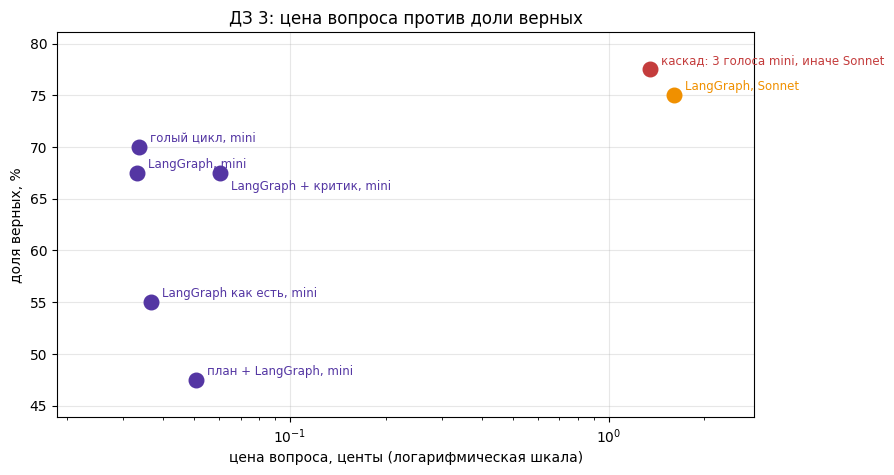

In [36]:
def color_of(tag):
    return COLORS["red"] if "каскад" in tag else COLORS["amber"] if "Sonnet" in tag else COLORS["teal"] if "smolagents" in tag else COLORS["violet"]

def money_chart(tags, path, title):
    table = report(tags)
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.set_xscale("log")
    for _, r in table.iterrows():
        ax.scatter(r["центов на вопрос"], r["доля"] * 100, s=110, color=color_of(r["конфигурация"]), zorder=3)
    ax.margins(x=0.15, y=0.12)
    fig.canvas.draw()
    placed = []
    for _, r in table.sort_values("центов на вопрос").iterrows():
        for dx, dy in [(8, 4), (8, -12), (-8, 4), (-8, -12), (8, 16), (8, -24)]:
            label = ax.annotate(r["конфигурация"], (r["центов на вопрос"], r["доля"] * 100), xytext=(dx, dy), textcoords="offset points",
                                fontsize=8.5, ha="left" if dx > 0 else "right", color=color_of(r["конфигурация"]))
            box = label.get_window_extent()
            if not any(box.overlaps(b) for b in placed) or dy == -24:
                break
            label.remove()
        placed.append(box)
    ax.set_xlabel("цена вопроса, центы (логарифмическая шкала)"); ax.set_ylabel("доля верных, %")
    ax.set_title(title); ax.grid(alpha=0.3)
    fig.savefig(path, dpi=150, bbox_inches="tight")
    return table

TABLE = money_chart(ROWS, "img/money_all.png", "ДЗ 3: цена вопроса против доли верных")
TABLE

In [37]:
from langchain.agents.middleware import ModelCallLimitMiddleware

def capped_agent(limit):
    return create_agent(lc_model(CHEAP), tools=LC_TOOLS, system_prompt=AGENT_SYSTEM,
                        middleware=[ModelCallLimitMiddleware(run_limit=limit, exit_behavior="end")])

TAG["now"] = "потолок"
CAP = None
for t in tasks[:10]:
    before = len(CALLS)
    answer = capped_agent(2).invoke({"messages": [{"role": "user", "content": t["question"]}]})["messages"][-1].content
    if "limit" in str(answer).lower():
        CAP = {"вопрос": t["question"], "ответ LangGraph после обрыва": answer, "вызовов модели": len(CALLS) - before,
               "ответ голого цикла при max_steps=2": bare_agent(t["question"], max_steps=2), "эталон": t["answer"]}
        break
CAP

{'вопрос': 'On what date did Ukraine boycott the closing ceremony of the 2026 Winter Paralympics?',
 'ответ LangGraph после обрыва': 'Model call limits exceeded: run limit (2/2)',
 'вызовов модели': 2,
 'ответ голого цикла при max_steps=2': "The date of Ukraine's boycott of the closing ceremony of the 2026 Winter Paralympics is not specified in the available information.",
 'эталон': '15 March'}

In [39]:
from langchain.agents.middleware import HumanInTheLoopMiddleware, ModelCallLimitMiddleware
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.types import Command

@tool
def send_summary(to: str, text: str) -> str:
    """Send a short summary to a colleague by email. Irreversible."""
    return f"sent to {to}: {text}"

TAG["now"] = "человек в контуре"
guarded = create_agent(lc_model(CHEAP), tools=LC_TOOLS + [send_summary], system_prompt=AGENT_SYSTEM.replace(" reply with the short answer only, no explanation", " report what you did"),
                       checkpointer=InMemorySaver(), middleware=[HumanInTheLoopMiddleware(interrupt_on={"send_summary": True})])
thread = {"configurable": {"thread_id": "demo-1"}, "recursion_limit": 14}
out = guarded.invoke({"messages": [{"role": "user", "content": "Find who won the 2026 FIFA World Cup final and email a one-line summary to boss@example.com"}]}, thread)
out["__interrupt__"][0].value["action_requests"]

[{'name': 'send_summary',
  'args': {'to': 'boss@example.com',
   'text': 'Spain won the 2026 FIFA World Cup final against Argentina.'},
  'description': "Tool execution requires approval\n\nTool: send_summary\nArgs: {'to': 'boss@example.com', 'text': 'Spain won the 2026 FIFA World Cup final against Argentina.'}"}]

In [40]:
out = guarded.invoke(Command(resume={"decisions": [{"type": "reject", "message": "Добавь в письмо счёт финала"}]}), thread)
out.get("__interrupt__", [None])[0].value["action_requests"] if out.get("__interrupt__") else out["messages"][-1].content

[{'name': 'send_summary',
  'args': {'to': 'boss@example.com',
   'text': 'Spain won the 2026 FIFA World Cup final against Argentina with a score of 2-0.'},
  'description': "Tool execution requires approval\n\nTool: send_summary\nArgs: {'to': 'boss@example.com', 'text': 'Spain won the 2026 FIFA World Cup final against Argentina with a score of 2-0.'}"}]

In [41]:
out = guarded.invoke(Command(resume={"decisions": [{"type": "approve"}]}), thread)
print(out["messages"][-1].content)
print("сообщений в сохранённом состоянии:", len(guarded.get_state(thread).values["messages"]))

I found that Spain won the 2026 FIFA World Cup final against Argentina with a score of 2-0. I then sent a one-line summary of this information to boss@example.com.
сообщений в сохранённом состоянии: 12


In [43]:
T = report(ROWS).set_index("конфигурация")
ok = lambda tag: T.loc[tag, "верно"]
per_q = lambda tag: T.loc[tag, "центов на вопрос"]
per_ok = lambda tag: T.loc[tag, "центов за верный"]
TAX_NOTE = f"После починки первый запрос LangGraph весит столько же, сколько у голого цикла: 176 токенов, на 15 байт больше из-за служебных полей. Перенос вслепую был на 32 токена легче, потому что tool(fn) молча выбросил описания аргументов, а граф падал с GraphRecursionError вместо ответа: {ok(LG_RAW)} против {ok(LG)} после починки. В базовом цикле фреймворк ничего не добавил ни к качеству, ни к цене; его польза в том, что критик графом, лимит вызовов и остановка на подтверждение человеком пишутся в несколько строк."
CONCLUSIONS = [
    f"Дало прирост: каскад, {ok(CASCADE)} против {ok(LG)} у mini, верный ответ на {round((1 - per_ok(CASCADE) / per_ok(STRONG_ROW)) * 100)}% дешевле Sonnet в одиночку. Но наверх ушло {N_ESCALATED} из {len(tasks)} вопросов, вопрос стоит в {round(per_q(CASCADE) / per_q(LG))} раз дороже mini, а разница с Sonnet ({ok(STRONG_ROW)}) на 40 вопросах лежит в пределах шума. Ещё помогла починка LangGraph: {ok(LG_RAW)} стало {ok(LG)}.",
    f"Дорогое украшение: критик (исправил {FIXED}, испортил {BROKEN}, итог {ok(CRITIC)} против {ok(LG)} без него при цене в {per_q(CRITIC) / per_q(LG):.1f} раза выше) и план ({ok(PLAN)} против {ok(LG)} и в {per_q(PLAN) / per_q(LG):.1f} раза дороже).",
]

def md_table(df):
    head = "| " + " | ".join(map(str, df.columns)) + " |\n|" + "---|" * len(df.columns)
    return head + "\n" + "\n".join("| " + " | ".join(str(v).replace("\n", " ").replace("|", "/") for v in row) + " |" for row in df.values)

TABLE = report(ROWS)
spent = sum(c["cost"] for c in CALLS)
cas, strong = TABLE[TABLE["конфигурация"] == CASCADE].iloc[0], TABLE[TABLE["конфигурация"] == STRONG_ROW].iloc[0]
readme = f"""# ДЗ 3. Фреймворк, критик, голосование

Агент из первой домашки на {len(tasks)} вопросах. Модели: `{CHEAP}` и `{STRONG}`. Фреймворк: LangGraph.
Запуск: `homework03.ipynb`, ключ `OPENROUTER_API_KEY` в `.env` или в секретах Colab, Run All. Прогон стоил ${spent:.2f}.

## Итог

{md_table(TABLE)}

![цена вопроса против доли верных](img/money_all.png)

- {CONCLUSIONS[0]}
- {CONCLUSIONS[1]}

## Налог фреймворка на пустом запросе

{md_table(pd.DataFrame(EMPTY))}

Разница в первом вызове: **{TAX:+d} токенов**. {TAX_NOTE}

## Критик и каскад

- Критик: исправил **{FIXED}**, испортил **{BROKEN}**.
- Каскад: наверх ушло **{N_ESCALATED} из {len(tasks)}** ({N_ESCALATED / len(tasks):.0%}); цена верного ответа {cas["центов за верный"]} цента против {strong["центов за верный"]} у сильной модели.

## Проверка проверки

{md_table(pd.DataFrame(CHECK))}

{CHECK_NOTE}

## Потолок на деньги

Лимит в два вызова модели (`ModelCallLimitMiddleware`):

{md_table(pd.DataFrame([CAP]).T.reset_index().set_axis(["", "значение"], axis=1)) if CAP else "на первых десяти вопросах лимит не сработал"}
"""
Path("README.md").write_text(readme, encoding="utf-8")
print(readme)

# ДЗ 3. Фреймворк, критик, голосование

Агент из первой домашки на 40 вопросах. Модели: `openai/gpt-4o-mini` и `anthropic/claude-sonnet-4.6`. Фреймворк: LangGraph.
Запуск: `homework03.ipynb`, ключ `OPENROUTER_API_KEY` в `.env` или в секретах Colab, Run All. Прогон стоил $1.27.

## Итог

| конфигурация | верно | доля | вызовов на вопрос | токенов на вопрос | центов на вопрос | центов за верный |
|---|---|---|---|---|---|---|
| голый цикл, mini | 28/40 | 0.7 | 3.6 | 2004 | 0.0336 | 0.048 |
| LangGraph как есть, mini | 22/40 | 0.55 | 4.0 | 2434 | 0.0367 | 0.0668 |
| LangGraph, mini | 27/40 | 0.675 | 3.7 | 2000 | 0.0332 | 0.0492 |
| LangGraph + критик, mini | 27/40 | 0.675 | 6.2 | 3639 | 0.0603 | 0.0894 |
| каскад: 3 голоса mini, иначе Sonnet | 31/40 | 0.775 | 13.6 | 9253 | 1.3481 | 1.7395 |
| план + LangGraph, mini | 19/40 | 0.475 | 5.1 | 2917 | 0.0507 | 0.1067 |
| LangGraph, Sonnet | 30/40 | 0.75 | 3.5 | 4376 | 1.6039 | 2.1385 |

![цена вопроса против доли верных](img/money_all.png)

- Д